In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
# importing featured engineer train and test data

X_train_fe = pd.read_csv('../Dataset/X_train_fe.csv')
X_test_fe = pd.read_csv('../Dataset/X_test_fe.csv')
X_train_ts = pd.read_csv('../Dataset/X_train.csv')
X_test_ts = pd.read_csv('../Dataset/X_test.csv')
y_train = pd.read_csv('../Dataset/y_train.csv')
y_test = pd.read_csv('../Dataset/y_test.csv')

In [11]:
print('X_train_fe Features:', X_train_fe.shape[1])
print('X_train Features:', X_train_ts.shape[1])

print('X_train_fe Columns:', X_train_fe.columns)
print('X_train Columns:', X_train_ts.columns)

X_train_fe Features: 20
X_train Features: 12
X_train_fe Columns: Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'color', 'total_acidity', 'acidity_ratio',
       'extra_sulphur_dioxide', 'sulphur_dioxide_ratio', 'sugar_alcohol_ratio',
       'density_alcohol_ratio', 'alcohol_sulphates', 'alcohol_acidity'],
      dtype='str')
X_train Columns: Index(['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar',
       'chlorides', 'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'color'],
      dtype='str')


In [14]:
y_train = y_train.squeeze()
y_test = y_test.squeeze()

In [6]:
bs_result = pd.read_csv('../Report/Results/baseline_results.csv', index_col=0)

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate

test_rf =  RandomForestRegressor(random_state=42)
test_rf.fit(X_train_ts, y_train)
test_prediction = test_rf.predict(X_test_ts)

In [30]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

test_table = pd.DataFrame({
    'R² Score': [r2_score(y_test, test_prediction)],
    'MAE Score': [mean_absolute_error(y_test, test_prediction)],
    'RMSE Score': [root_mean_squared_error(y_test, test_prediction)]
})
test_table

,R² Score,MAE Score,RMSE Score
0,0.4138,0.508177,0.663888


In [22]:
feature_importance = pd.DataFrame({
    'Features': X_train_ts.columns,
    'Importance': test_rf.feature_importances_
})
feature_importance = feature_importance.sort_values(by='Importance', ascending=False)
feature_importance 

,Features,Importance
10,alcohol,0.263777
1,volatile_acidity,0.115381
5,free_sulfur_dioxide,0.094150
9,sulphates,0.083396
6,total_sulfur_dioxide,0.074483
8,pH,0.070441
3,residual_sugar,0.062588
4,chlorides,0.060620
0,fixed_acidity,0.059187
7,density,0.058149


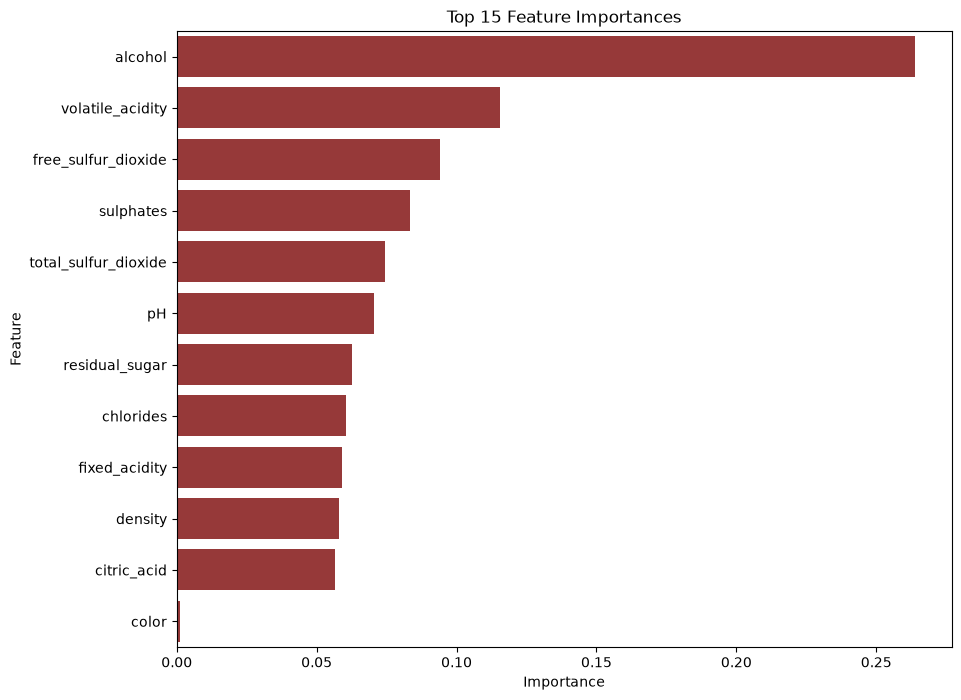

In [24]:
plt.figure(figsize=(10, 8))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Features',
    color='brown'
)
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

In [34]:
from sklearn.model_selection import cross_validate

test_rfg =  RandomForestRegressor(random_state=42)
cvn = cross_validate(
    test_rfg,
    X_train_ts,
    y_train,
    cv=3,
    scoring={
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
    }
)


In [35]:
cvn_table = pd.DataFrame({
    'R² Score': [cvn['test_r2'].mean()],
    'MAE Score': [-cvn['test_mae'].mean()],
    'RMSE Score': [-cvn['test_rmse'].mean()]
})
cvn_table

,R² Score,MAE Score,RMSE Score
0,0.354473,0.547427,0.708893


In [43]:
fe_rfg = RandomForestRegressor(random_state=42)

fe_cvn = cross_validate(
    fe_rfg, 
    X_train_fe,
    y_train,
    cv=3,
    scoring={
    'r2': 'r2',
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error'
    }
)

In [44]:
fe_cvn_table = pd.DataFrame({
    'R² Score': [fe_cvn['test_r2'].mean()],
    'MAE Score': [-fe_cvn['test_mae'].mean()],
    'RMSE Score': [-fe_cvn['test_rmse'].mean()]
})
fe_cvn_table

,R² Score,MAE Score,RMSE Score
0,0.357636,0.547502,0.707166


In [45]:
compare_table = pd.concat([cvn_table, fe_cvn_table], ignore_index=True)
compare_table

,R² Score,MAE Score,RMSE Score
0,0.354473,0.547427,0.708893
1,0.357636,0.547502,0.707166
